# 04 · Modelos finales, estabilidad y generalización (Etapa III)

**Fases CRISP-DM:** modelado comparativo y evaluación.

1. **Ensambles:** Random Forest (bagging), LightGBM y XGBoost (boosting),
   con búsqueda de hiperparámetros.
2. **Comparación** con la línea base del notebook 03, en clasificación
   binaria y multiclase.
3. **Explicabilidad:** importancia por permutación.
4. **Estabilidad de variables** entre entrenamiento y prueba oficial
   (Concept Drift dentro de IoMT).
5. **Generalización cruzada** entre red tradicional (CIC-DDoS2019) e IoMT
   (CICIoMT2024). Esta sección es opcional y se ejecuta solo si los CSV
   de CIC-DDoS2019 están descargados (ver `DESCARGA_DATOS.txt`).

In [1]:
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ.resolve()))

from src.evaluate import configurar_graficos
configurar_graficos()

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from src.data_loader import (
    CLASES, CARPETA_MODELOS, CARPETA_RESULTADOS,
    cargar_procesado, cargar_variables, cargar_ddos2019,
)
from src.features import (
    preprocesador, estabilidad_variables,
    homologar_iomt, homologar_cicflowmeter, normalizar_por_dominio,
    VARIABLES_COMUNES, VARIABLES_COMUNES_FIABLES,
)
from src.evaluate import evaluar, matriz_confusion, guardar_tabla

config = cargar_variables()
variables = config["variables"]
SEMILLA = config["semilla"]

train = cargar_procesado("train")
val = cargar_procesado("val")
test = cargar_procesado("test")

print("Variables:", len(variables))
print("Entrenamiento:", train.shape, "| Validación:", val.shape, "| Prueba oficial:", test.shape)

Variables: 34
Entrenamiento: (478633, 36) | Validación: (119659, 36) | Prueba oficial: (415658, 36)


## 1. Configuración de la búsqueda de hiperparámetros

La búsqueda se hace sobre una **muestra estratificada** del entrenamiento,
con validación cruzada de 3 particiones y F1 macro como criterio. El mejor
conjunto de hiperparámetros se reentrena luego con todo el entrenamiento.

El desbalance se trata con pesos por muestra (`compute_sample_weight`),
igual para los tres modelos. Aumentar `MUESTRA_BUSQUEDA` o
`ITERACIONES_BUSQUEDA` mejora la búsqueda, pero aumenta el tiempo.

In [2]:
MUESTRA_BUSQUEDA = 50_000
ITERACIONES_BUSQUEDA = 8


def candidatos():
    return {
        "Random Forest": (
            RandomForestClassifier(n_jobs=-1, random_state=SEMILLA),
            {
                "n_estimators": randint(100, 300),
                "max_depth": [None, 10, 20, 30],
                "min_samples_leaf": randint(1, 20),
                "max_features": ["sqrt", 0.3, 0.5],
            },
        ),
        "LightGBM": (
            LGBMClassifier(n_jobs=-1, random_state=SEMILLA, verbose=-1),
            {
                "n_estimators": randint(100, 600),
                "learning_rate": loguniform(0.02, 0.3),
                "num_leaves": randint(15, 128),
                "min_child_samples": randint(10, 100),
                "subsample": uniform(0.6, 0.4),
                "subsample_freq": [1],
                "colsample_bytree": uniform(0.6, 0.4),
            },
        ),
        "XGBoost": (
            XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEMILLA),
            {
                "n_estimators": randint(100, 600),
                "learning_rate": loguniform(0.02, 0.3),
                "max_depth": randint(3, 10),
                "min_child_weight": randint(1, 10),
                "subsample": uniform(0.6, 0.4),
                "colsample_bytree": uniform(0.6, 0.4),
            },
        ),
    }


def muestra_estratificada(datos, n, columna="clase"):
    if len(datos) <= n:
        return datos
    return train_test_split(
        datos, train_size=n, stratify=datos[columna], random_state=SEMILLA
    )[0]


def ajustar(nombre, objetivo, variables=variables, datos=train):
    """Busca hiperparámetros y reentrena con todos los datos de `datos`."""
    estimador, espacio = candidatos()[nombre]
    pipeline = Pipeline([("prep", preprocesador()), ("modelo", estimador)])

    estrato = "clase" if "clase" in datos else objetivo
    muestra = muestra_estratificada(datos, MUESTRA_BUSQUEDA, estrato)
    busqueda = RandomizedSearchCV(
        pipeline,
        {f"modelo__{k}": v for k, v in espacio.items()},
        n_iter=ITERACIONES_BUSQUEDA,
        scoring="f1_macro",
        cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA),
        random_state=SEMILLA,
        refit=False,
    )
    busqueda.fit(
        muestra[variables], muestra[objetivo],
        modelo__sample_weight=compute_sample_weight("balanced", muestra[objetivo]),
    )

    modelo = clone(pipeline).set_params(**busqueda.best_params_)
    inicio = time.perf_counter()
    modelo.fit(
        datos[variables], datos[objetivo],
        modelo__sample_weight=compute_sample_weight("balanced", datos[objetivo]),
    )
    return modelo, {
        "Mejores hiperparámetros": {
            k.removeprefix("modelo__"): v for k, v in busqueda.best_params_.items()
        },
        "F1 macro CV": busqueda.best_score_,
        "Segundos de entrenamiento": time.perf_counter() - inicio,
    }

## 2. Entrenamiento y evaluación

Se entrenan los tres ensambles para la tarea binaria (benigno vs. DDoS)
y para la multiclase (benigno, DDoS SYN y DDoS UDP).

In [3]:
tareas = {"binaria": "etiqueta", "multiclase": "clase"}
modelos = {}
busquedas = []
resultados = {"binaria": {"val": [], "test": []},
              "multiclase": {"val": [], "test": []}}

for tarea, objetivo in tareas.items():
    for nombre in candidatos():
        print(f"Ajustando {nombre} ({tarea})...")
        modelo, info = ajustar(nombre, objetivo)
        modelos[(tarea, nombre)] = modelo
        busquedas.append({"Tarea": tarea, "Modelo": nombre, **info})

        for particion, datos in [("val", val), ("test", test)]:
            resultados[tarea][particion].append({"Modelo": nombre, **evaluar(
                modelo, datos[variables], datos[objetivo], tarea,
                clase_real=datos["clase"] if tarea == "binaria" else None,
            )})

busquedas = pd.DataFrame(busquedas).set_index(["Tarea", "Modelo"])
display(busquedas)
guardar_tabla(busquedas, "busqueda_hiperparametros")

Ajustando Random Forest (binaria)...


Ajustando LightGBM (binaria)...


Ajustando XGBoost (binaria)...


Ajustando Random Forest (multiclase)...


Ajustando LightGBM (multiclase)...


Ajustando XGBoost (multiclase)...


Mejores hiperparámetros  \
Tarea      Modelo                                                             
binaria    Random Forest  {'max_depth': 30, 'max_features': 'sqrt', 'min...   
           LightGBM       {'colsample_bytree': 0.749816047538945, 'learn...   
           XGBoost        {'colsample_bytree': 0.7164916560792167, 'lear...   
multiclase Random Forest  {'max_depth': 30, 'max_features': 'sqrt', 'min...   
           LightGBM       {'colsample_bytree': 0.6092249700165663, 'lear...   
           XGBoost        {'colsample_bytree': 0.6053059844639466, 'lear...   

                          F1 macro CV  Segundos de entrenamiento  
Tarea      Modelo                                                 
binaria    Random Forest     0.999702                   9.957042  
           LightGBM          0.999840                   2.587347  
           XGBoost           0.999725                   4.487380  
multiclase Random Forest     0.999716                  19.985545  
           LightGBM          0.999838                  22.683989  
           XGBoost           0.999838                  13.070111

PosixPath('/Users/makise/Documents/GitHub/Data-Science/deliverables/resultados/busqueda_hiperparametros.csv')

In [4]:
tablas = {
    (tarea, particion): pd.DataFrame(filas).set_index("Modelo")
    for tarea, por_particion in resultados.items()
    for particion, filas in por_particion.items()
}

for (tarea, particion), tabla in tablas.items():
    nombre = "validación" if particion == "val" else "prueba oficial"
    print(f"{tarea.capitalize()} — {nombre}")
    display(tabla.round(4))
    guardar_tabla(tabla, f"metricas_{tarea}_ensambles_{particion}")

Binaria — validación


,Accuracy,Precision DDoS,Recall DDoS,F1 DDoS,F1 macro,Tasa falsos positivos,PR-AUC,Recall SYN,Recall UDP,Falsas alarmas,Ataques no detectados
Modelo,,,,,,,,,,,
Random Forest,0.9999,1.0,0.9999,0.9999,0.9999,0.0,1.0,0.9998,0.9999,0,10
LightGBM,1.0000,1.0,0.9999,1.0000,1.0000,0.0,1.0,0.9999,1.0000,0,5
XGBoost,0.9999,1.0,0.9999,1.0000,0.9999,0.0,1.0,0.9999,1.0000,1,5


Binaria — prueba oficial


,Accuracy,Precision DDoS,Recall DDoS,F1 DDoS,F1 macro,Tasa falsos positivos,PR-AUC,Recall SYN,Recall UDP,Falsas alarmas,Ataques no detectados
Modelo,,,,,,,,,,,
Random Forest,0.9986,1.0,0.9985,0.9992,0.9958,0.0,1.0,0.9971,0.9996,0,574
LightGBM,0.9989,1.0,0.9988,0.9994,0.9967,0.0,1.0,0.9977,0.9997,0,456
XGBoost,0.9989,1.0,0.9988,0.9994,0.9966,0.0,1.0,0.9976,0.9997,0,466


Multiclase — validación


,Accuracy,Precision macro,Recall macro,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Tasa falsos positivos
Modelo,,,,,,,,
Random Forest,0.9999,0.9999,0.9999,0.9999,1.0,0.9998,0.9999,0.0
LightGBM,0.9999,0.9999,1.0000,0.9999,1.0,0.9999,0.9999,0.0
XGBoost,0.9999,0.9999,0.9999,0.9999,1.0,0.9999,0.9999,0.0


Multiclase — prueba oficial


,Accuracy,Precision macro,Recall macro,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Tasa falsos positivos
Modelo,,,,,,,,
Random Forest,0.9985,0.9948,0.9988,0.9968,1.0,0.9970,0.9995,0.0
LightGBM,0.9988,0.9957,0.9990,0.9973,1.0,0.9976,0.9995,0.0
XGBoost,0.9988,0.9958,0.9991,0.9974,1.0,0.9976,0.9996,0.0


## 3. Comparación con la línea base

Se agregan los resultados de la regresión logística y del árbol de
decisión obtenidos en el notebook 03 (escenario V2 en el caso binario).

Binaria — prueba oficial


,F1 DDoS,F1 macro,Recall SYN,Recall UDP,Tasa falsos positivos,Falsas alarmas,Ataques no detectados
Modelo,,,,,,,
Clase mayoritaria,0.9526,0.4763,1.0000,1.0000,1.0000,37607,0
Regresión logística,0.9992,0.9954,0.9970,0.9995,0.0005,18,609
Árbol de decisión,0.9991,0.9951,0.9969,0.9994,0.0002,8,666
Random Forest,0.9992,0.9958,0.9971,0.9996,0.0000,0,574
LightGBM,0.9994,0.9967,0.9977,0.9997,0.0000,0,456
XGBoost,0.9994,0.9966,0.9976,0.9997,0.0000,0,466


Multiclase — prueba oficial


,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Tasa falsos positivos
Modelo,,,,,
Clase mayoritaria,0.2207,0.0000,0.0000,1.0000,1.0000
Regresión logística,0.9968,0.9998,0.9971,0.9995,0.0002
Árbol de decisión,0.9963,0.9997,0.9968,0.9994,0.0003
Random Forest,0.9968,1.0000,0.9970,0.9995,0.0000
LightGBM,0.9973,1.0000,0.9976,0.9995,0.0000
XGBoost,0.9974,1.0000,0.9976,0.9996,0.0000


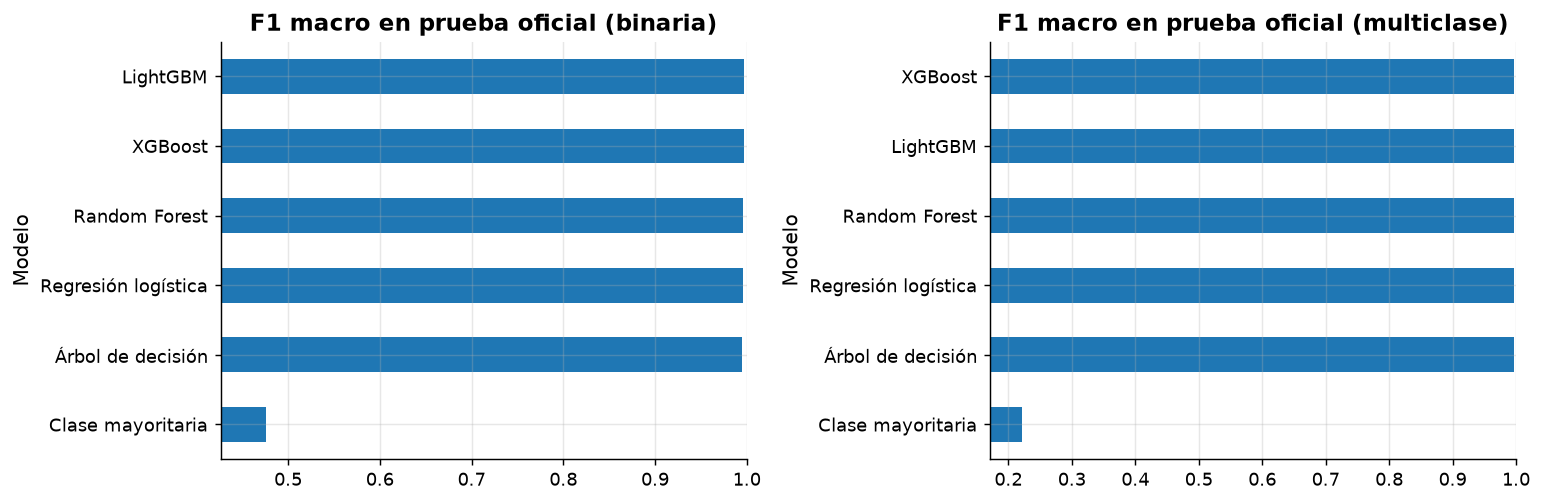

PosixPath('/Users/makise/Documents/GitHub/Data-Science/deliverables/resultados/comparacion_binaria_prueba_oficial.csv')

In [5]:
base_binaria = (
    pd.read_csv(CARPETA_RESULTADOS / "metricas_prueba_oficial.csv",
                index_col=["Escenario", "Modelo"])
    .loc["V2: benigno + SYN + UDP"]
)
base_multi = pd.read_csv(
    CARPETA_RESULTADOS / "metricas_multiclase_base_prueba_oficial.csv",
    index_col="Modelo",
)

comparacion = {
    "binaria": pd.concat([base_binaria, tablas[("binaria", "test")]]),
    "multiclase": pd.concat([base_multi, tablas[("multiclase", "test")]]),
}
columnas_clave = {
    "binaria": ["F1 DDoS", "F1 macro", "Recall SYN", "Recall UDP",
                "Tasa falsos positivos", "Falsas alarmas", "Ataques no detectados"],
    "multiclase": ["F1 macro", "Recall Benigno", "Recall DDoS SYN",
                   "Recall DDoS UDP", "Tasa falsos positivos"],
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (tarea, tabla) in zip(axes, comparacion.items()):
    print(f"{tarea.capitalize()} — prueba oficial")
    display(tabla[columnas_clave[tarea]].round(4))
    tabla["F1 macro"].sort_values().plot.barh(ax=ax)
    ax.set_xlim(max(0, tabla["F1 macro"].min() - 0.05), 1)
    ax.set_title(f"F1 macro en prueba oficial ({tarea})")
plt.tight_layout()
plt.show()

guardar_tabla(comparacion["multiclase"], "comparacion_multiclase_prueba_oficial")
guardar_tabla(comparacion["binaria"], "comparacion_binaria_prueba_oficial")

El mejor modelo se elige según el **F1 macro en validación**, no en la
prueba oficial, para no seleccionar el modelo con los datos de evaluación.

Mejor modelo por tarea (según validación): {'binaria': 'LightGBM', 'multiclase': 'LightGBM'}


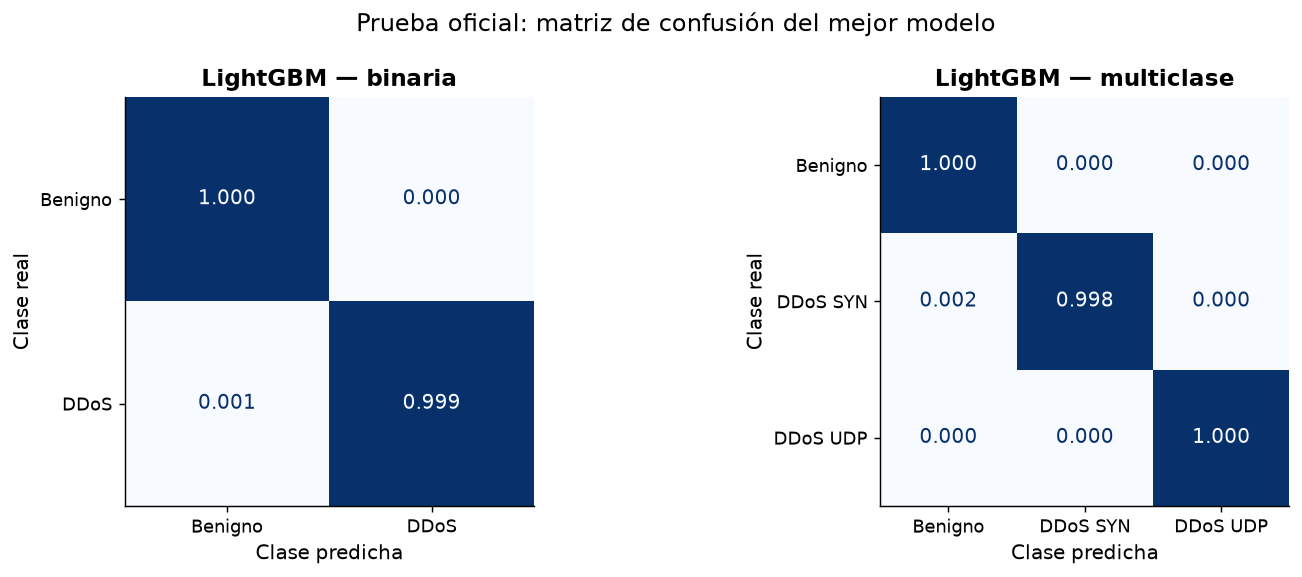

In [6]:
mejor = {
    tarea: tablas[(tarea, "val")]["F1 macro"].idxmax() for tarea in tareas
}
print("Mejor modelo por tarea (según validación):", mejor)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (tarea, objetivo) in zip(axes, tareas.items()):
    modelo = modelos[(tarea, mejor[tarea])]
    matriz_confusion(
        test[objetivo], modelo.predict(test[variables]), tarea,
        f"{mejor[tarea]} — {tarea}", ax=ax, normalizar="true",
    )
fig.suptitle("Prueba oficial: matriz de confusión del mejor modelo")
plt.tight_layout()
plt.show()

## 4. Explicabilidad: importancia por permutación

Se mide cuánto cae el F1 macro en validación al desordenar cada variable.
A diferencia de la importancia interna de los árboles, este método es
comparable entre modelos distintos.

,Importancia,Desviación
Variance,0.0006,0.0001
Rate,0.0003,0.0001
syn_flag_number,0.0002,0.0000
Tot sum,0.0001,0.0000
Header_Length,0.0001,0.0000
Protocol Type,0.0001,0.0000
Duration,0.0001,0.0000
ack_flag_number,0.0001,0.0000
Covariance,0.0001,0.0000
Tot size,0.0001,0.0000


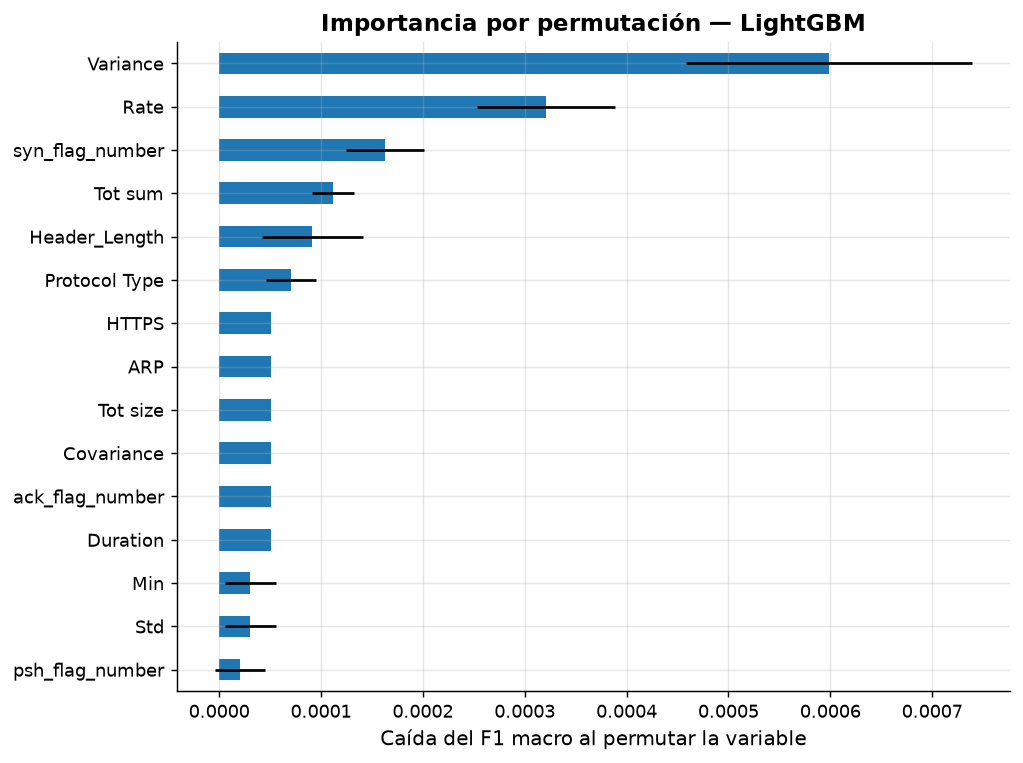

In [7]:
modelo_multi = modelos[("multiclase", mejor["multiclase"])]
muestra_val = muestra_estratificada(val, 20_000)

permutacion = permutation_importance(
    modelo_multi, muestra_val[variables], muestra_val["clase"],
    scoring="f1_macro", n_repeats=5, random_state=SEMILLA,
)
importancia = pd.DataFrame({
    "Importancia": permutacion.importances_mean,
    "Desviación": permutacion.importances_std,
}, index=variables).sort_values("Importancia", ascending=False)

display(importancia.head(15).round(4))

importancia.head(15).sort_values("Importancia")["Importancia"].plot.barh(
    figsize=(8, 6), xerr=importancia.head(15).sort_values("Importancia")["Desviación"],
    title=f"Importancia por permutación — {mejor['multiclase']}",
)
plt.xlabel("Caída del F1 macro al permutar la variable")
plt.tight_layout()
plt.show()

## 5. Estabilidad de las variables dentro de IoMT

Para cada clase se compara la distribución de cada variable entre
entrenamiento y prueba oficial:

- **KS** (Kolmogorov-Smirnov): 0 = distribuciones iguales, 1 = sin solapamiento.
- **PSI**: < 0,1 estable; 0,1–0,25 cambio moderado; > 0,25 cambio alto.

Se compara por clase para no confundir el cambio de las variables con
el cambio de proporciones entre clases.

In [8]:
estabilidad = pd.concat({
    CLASES[c]: estabilidad_variables(
        train[train["clase"] == c], test[test["clase"] == c], variables
    )
    for c in CLASES
}, axis=1)

ks = estabilidad.xs("KS", axis=1, level=1)
resumen_estabilidad = pd.DataFrame({
    "KS medio": ks.mean(axis=1),
    "KS máximo": ks.max(axis=1),
    "PSI medio": estabilidad.xs("PSI", axis=1, level=1).mean(axis=1),
}).join(importancia["Importancia"]).sort_values("KS medio")

display(resumen_estabilidad.round(4))
guardar_tabla(resumen_estabilidad, "estabilidad_variables_iomt")

,KS medio,KS máximo,PSI medio,Importancia
Variable,,,,
SMTP,0.0000,0.0000,0.0000,0.0000
DHCP,0.0000,0.0000,0.0000,0.0000
SSH,0.0000,0.0000,0.0000,0.0000
IRC,0.0000,0.0000,0.0000,0.0000
IGMP,0.0000,0.0000,0.0001,0.0000
cwr_flag_number,0.0000,0.0001,0.0001,0.0000
Telnet,0.0000,0.0001,0.0000,0.0000
ece_flag_number,0.0001,0.0001,0.0003,0.0000
fin_flag_number,0.0009,0.0013,0.0009,0.0000


PosixPath('/Users/makise/Documents/GitHub/Data-Science/deliverables/resultados/estabilidad_variables_iomt.csv')

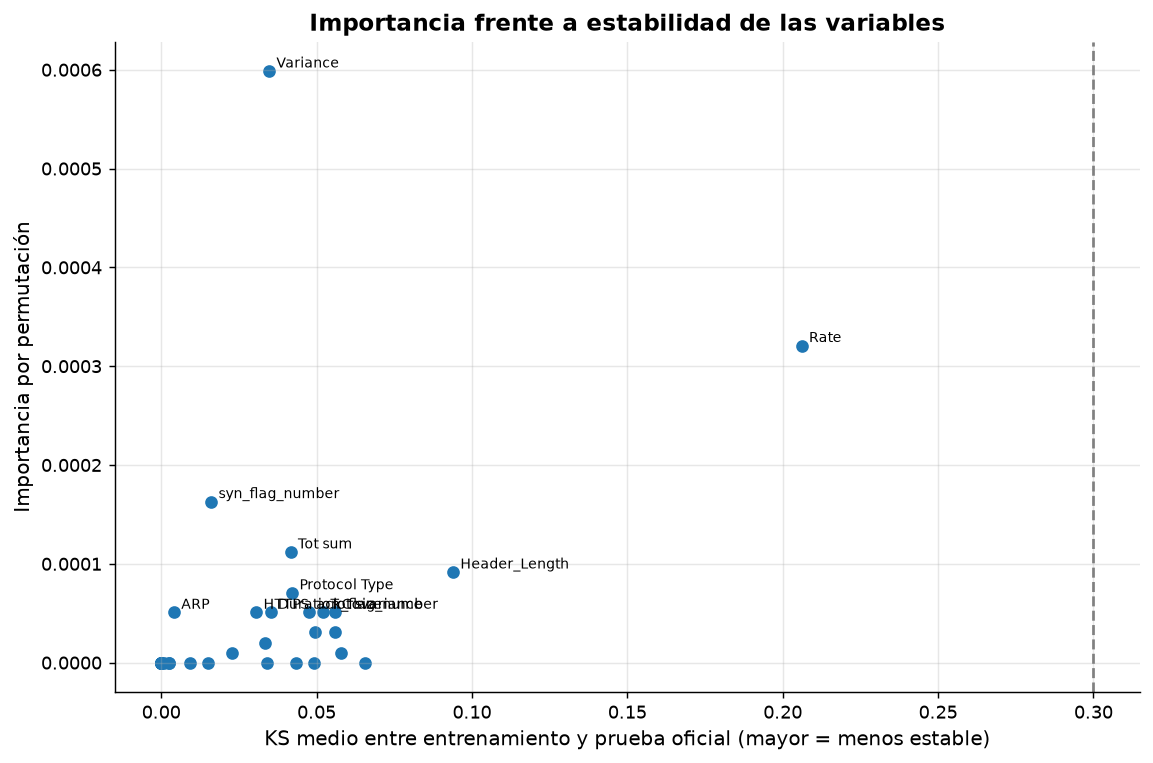

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(resumen_estabilidad["KS medio"], resumen_estabilidad["Importancia"])
for variable, fila in resumen_estabilidad.nlargest(12, "Importancia").iterrows():
    ax.annotate(variable, (fila["KS medio"], fila["Importancia"]),
                fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.axvline(0.3, color="gray", linestyle="--")
ax.set_xlabel("KS medio entre entrenamiento y prueba oficial (mayor = menos estable)")
ax.set_ylabel("Importancia por permutación")
ax.set_title("Importancia frente a estabilidad de las variables")
plt.tight_layout()
plt.show()

Las variables **importantes y estables** (abajo a la izquierda en KS,
arriba en importancia) son candidatas para una detección robusta.
Las variables **importantes e inestables** son un riesgo: el modelo
depende de ellas, pero cambian entre capturas.

### Prueba de robustez

Se reentrena el mejor modelo multiclase, con los mismos hiperparámetros,
sin las variables cuyo KS medio supera `UMBRAL_KS`. Si el desempeño en la
prueba oficial se mantiene o mejora, el modelo no depende de esas variables.

In [10]:
UMBRAL_KS = 0.3

inestables = resumen_estabilidad.index[resumen_estabilidad["KS medio"] > UMBRAL_KS].tolist()
estables = [v for v in variables if v not in inestables]
print(f"Variables inestables (KS medio > {UMBRAL_KS}):", inestables or "ninguna")

if inestables and estables:
    robusto = clone(modelo_multi).fit(
        train[estables], train["clase"],
        modelo__sample_weight=compute_sample_weight("balanced", train["clase"]),
    )
    robustez = pd.DataFrame([
        {"Variables": f"Todas ({len(variables)})",
         **evaluar(modelo_multi, test[variables], test["clase"], "multiclase")},
        {"Variables": f"Solo estables ({len(estables)})",
         **evaluar(robusto, test[estables], test["clase"], "multiclase")},
    ]).set_index("Variables")
    display(robustez.round(4))
    guardar_tabla(robustez, "robustez_variables_estables")

Variables inestables (KS medio > 0.3): ninguna


## 6. Generalización cruzada: red tradicional e IoMT

Como red tradicional se usa **CIC-DDoS2019**, que contiene los mismos dos
ataques que el experimento IoMT: **SYN flood** y **UDP flood**. Eso permite
comparar ataque con ataque, tanto en la tarea binaria como en la multiclase.

CIC-DDoS2019 tiene muy poco tráfico benigno. El cargador conserva todo el
benigno de todos los archivos y toma una muestra de hasta
`MAX_POR_ATAQUE` flujos de cada ataque.

**Homologación:** los extractores son distintos (CICIoMT2024 resume
ventanas de paquetes y CIC-DDoS2019 resume flujos con CICFlowMeter-V3).
Se usan variables con un significado equivalente: proporción de TCP/UDP,
proporción de cada bandera TCP, longitudes de paquete (mínimo, máximo,
media y desviación) y tasa de paquetes.

Al comparar los datos reales de ambos dominios se detectaron dos
diferencias de medición, que se corrigen (detalle en la sección 6.1):

1. **Longitud de paquete:** CICIoMT2024 mide el paquete completo (un SYN
   pesa 54 bytes = 14 Ethernet + 20 IP + 20 TCP), mientras que
   CICFlowMeter mide solo la carga útil (6 bytes en el mismo SYN). Se
   suman las cabeceras a CICFlowMeter (`alinear=True`).
2. **Banderas SYN y ACK:** en CIC-DDoS2019 el SYN flood tiene
   `SYN Flag Count` = 0 y `ACK Flag Count` = 1 en todos los flujos, un
   error conocido de CICFlowMeter-V3. Estas dos banderas se excluyen.

La homologación sigue siendo aproximada y debe reportarse como limitación.

| Entrenamiento | Evaluación | Propósito |
|---|---|---|
| IoMT | IoMT | Línea base dentro del dominio |
| Tradicional | Tradicional | Línea base dentro del dominio |
| Tradicional | IoMT | ¿Un NIDS de red tradicional sirve en IoMT? |
| IoMT | Tradicional | Dirección inversa |

In [11]:
MAX_POR_ATAQUE = 200_000
MUESTRA_DOMINIO = 300_000

ddos2019 = cargar_ddos2019(MAX_POR_ATAQUE)
HAY_TRADICIONAL = ddos2019 is not None

if not HAY_TRADICIONAL:
    print("No se encontró CIC-DDoS2019 en data/raw/CIC-DDoS2019/.")
    print("Se omite la generalización cruzada (ver DESCARGA_DATOS.txt).")
else:
    print("Registros CIC-DDoS2019 utilizados:", len(ddos2019))
    display(ddos2019["clase"].map(CLASES).value_counts().to_frame("Registros"))

    # IoMT: se parte de los datos limpios con todas las columnas originales,
    # porque la homologación usa variables que el notebook 02 pudo descartar
    iomt_train = homologar_iomt(cargar_procesado("train_limpio"))
    iomt_test = homologar_iomt(cargar_procesado("test_limpio"))

    trad = homologar_cicflowmeter(ddos2019, alinear=True)
    trad_train, trad_test = train_test_split(
        trad, test_size=0.30, stratify=trad["clase"], random_state=SEMILLA
    )

    dominios = {
        "IoMT": {
            "train": muestra_estratificada(iomt_train, MUESTRA_DOMINIO),
            "test": iomt_test,
        },
        "Tradicional": {
            "train": muestra_estratificada(trad_train, MUESTRA_DOMINIO),
            "test": trad_test,
        },
    }
    display(pd.DataFrame({
        (dominio, particion): datos["clase"].map(CLASES).value_counts()
        for dominio, partes in dominios.items()
        for particion, datos in partes.items()
    }))

Registros CIC-DDoS2019 utilizados: 456965


,Registros
clase,
DDoS SYN,200000
DDoS UDP,200000
Benigno,56965


IoMT         Tradicional       
           train    test       train   test
clase                                      
DDoS UDP  103379  205654      131301  60000
DDoS SYN   99980  172397      131301  60000
Benigno    96641   37607       37398  17090

### 6.1 Mejora de la homologación (estudio de ablación)

Se compara la homologación original con las correcciones, aplicándolas
una a una. Para que la comparación sea rápida y justa se usa el mismo
LightGBM con hiperparámetros fijos en todas las variantes.

También se prueba **normalizar cada dominio por percentiles** (longitudes
y tasa), una forma simple de adaptación de dominio que no usa etiquetas.

La comparación usa los datos de evaluación de ambos dominios, por lo que
es un análisis de la homologación y no una selección de hiperparámetros.
Se reportan todas las variantes, no solo la mejor.

A. Original  B. Longitud alineada  \
Tarea      Dirección                                                      
binaria    IoMT → IoMT                     0.9935                0.9935   
           IoMT → Tradicional              0.3305                0.5857   
           Tradicional → IoMT              0.1918                0.3873   
           Tradicional → Tradicional       0.9996                0.9996   
multiclase IoMT → IoMT                     0.9950                0.9950   
           IoMT → Tradicional              0.2956                0.3074   
           Tradicional → IoMT              0.1628                0.3134   
           Tradicional → Tradicional       0.9995                0.9995   
Promedio   Cruzado                         0.2452                0.3985   
           Mismo dominio                   0.9969                0.9969   

                                      C. B sin SYN/ACK  D. C sin tasa  \
Tarea      Dirección                                                    
binaria    IoMT → IoMT                          0.9969         0.9975   
           IoMT → Tradicional                   0.6261         0.5264   
           Tradicional → IoMT                   0.3271         0.4343   
           Tradicional → Tradicional            0.9626         0.9839   
multiclase IoMT → IoMT                          0.9979         0.9981   
           IoMT → Tradicional                   0.6799         0.4210   
           Tradicional → IoMT                   0.2860         0.4165   
           Tradicional → Tradicional            0.9906         0.9878   
Promedio   Cruzado                              0.4797         0.4495   
           Mismo dominio                        0.9870         0.9918   

                                      E. C + normalización  
Tarea      Dirección                                        
binaria    IoMT → IoMT                              0.7247  
           IoMT → Tradicional                       0.4084  
           Tradicional → IoMT                       0.3560  
           Tradicional → Tradicional                0.9684  
multiclase IoMT → IoMT                              0.7861  
           IoMT → Tradicional                       0.5434  
           Tradicional → IoMT                       0.0363  
           Tradicional → Tradicional                0.9756  
Promedio   Cruzado                                  0.3360  
           Mismo dominio                            0.8637

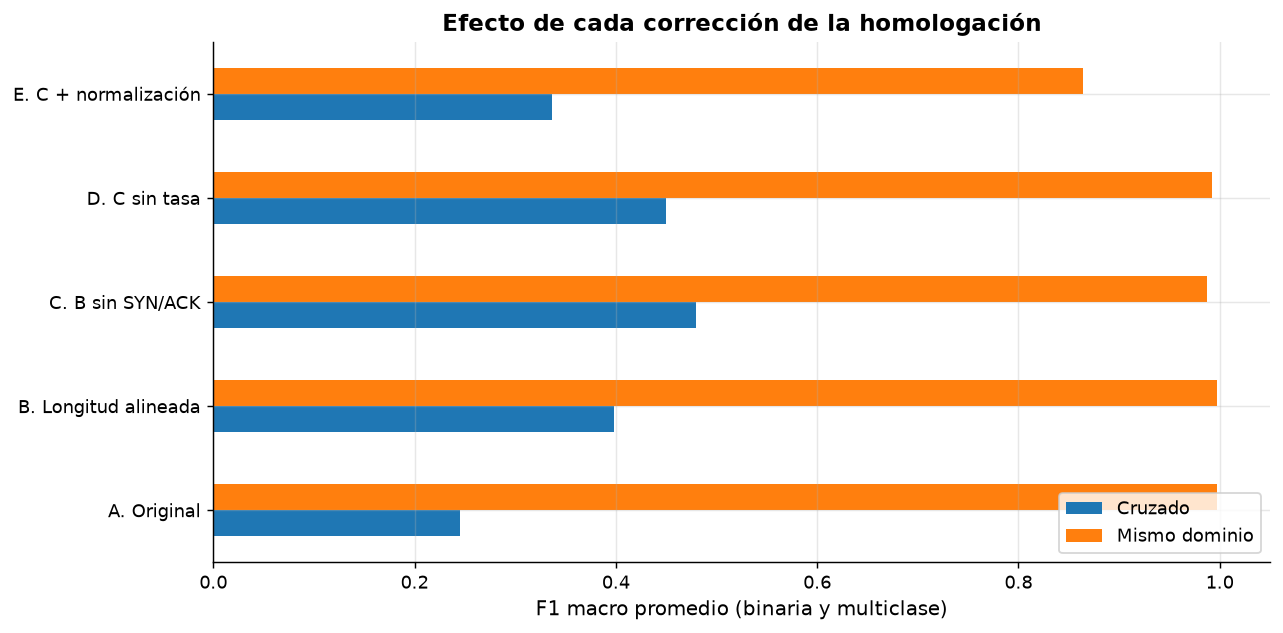

In [12]:
def experimento_homologacion(alinear, variables_usadas, normalizar):
    trad_v = homologar_cicflowmeter(ddos2019, alinear=alinear)
    trad_tr, trad_te = train_test_split(
        trad_v, test_size=0.30, stratify=trad_v["clase"], random_state=SEMILLA
    )
    partes_v = {
        "IoMT": [dominios["IoMT"]["train"], dominios["IoMT"]["test"]],
        "Tradicional": [muestra_estratificada(trad_tr, MUESTRA_DOMINIO), trad_te],
    }
    if normalizar:
        partes_v = {
            d: [normalizar_por_dominio(x, variables_usadas) for x in xs]
            for d, xs in partes_v.items()
        }

    filas = []
    for tarea, objetivo in tareas.items():
        for origen, (entrenamiento, _) in partes_v.items():
            modelo = LGBMClassifier(n_estimators=300, random_state=SEMILLA, verbose=-1)
            modelo.fit(
                entrenamiento[variables_usadas], entrenamiento[objetivo],
                sample_weight=compute_sample_weight("balanced", entrenamiento[objetivo]),
            )
            for destino, (_, evaluacion) in partes_v.items():
                filas.append({
                    "Tarea": tarea,
                    "Dirección": f"{origen} → {destino}",
                    "F1 macro": evaluar(
                        modelo, evaluacion[variables_usadas], evaluacion[objetivo], tarea
                    )["F1 macro"],
                })
    return pd.DataFrame(filas).set_index(["Tarea", "Dirección"])["F1 macro"]


if HAY_TRADICIONAL:
    sin_tasa = [v for v in VARIABLES_COMUNES_FIABLES if v != "tasa_paquetes"]
    variantes = {
        "A. Original": (False, VARIABLES_COMUNES, False),
        "B. Longitud alineada": (True, VARIABLES_COMUNES, False),
        "C. B sin SYN/ACK": (True, VARIABLES_COMUNES_FIABLES, False),
        "D. C sin tasa": (True, sin_tasa, False),
        "E. C + normalización": (True, VARIABLES_COMUNES_FIABLES, True),
    }
    ablacion = pd.DataFrame({
        nombre: experimento_homologacion(*config)
        for nombre, config in variantes.items()
    })
    cruzadas = ablacion.index.get_level_values("Dirección").isin(
        ["IoMT → Tradicional", "Tradicional → IoMT"]
    )
    promedio_cruzado = ablacion[cruzadas].mean()
    promedio_mismo = ablacion[~cruzadas].mean()
    ablacion.loc[("Promedio", "Cruzado"), :] = promedio_cruzado
    ablacion.loc[("Promedio", "Mismo dominio"), :] = promedio_mismo
    display(ablacion.round(4))
    guardar_tabla(ablacion, "ablacion_homologacion")

    ax = ablacion.loc["Promedio"].T.plot.barh(
        figsize=(10, 5), title="Efecto de cada corrección de la homologación"
    )
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("F1 macro promedio (binaria y multiclase)")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

**Resultado esperado de la ablación:**

- Alinear la longitud (B) y quitar SYN/ACK (C) mejoran el F1 cruzado sin
  perder desempeño dentro de cada dominio.
- Normalizar por percentiles (E) empeora incluso dentro de IoMT: la prueba
  oficial de IoMT tiene un 91 % de ataques y el entrenamiento un 68 %, así
  que los percentiles se desplazan con la proporción de clases (*label
  shift*). Por eso se descarta.

En el resto de la sección se usa la variante con mejor F1 cruzado
promedio, que se elige automáticamente.

In [13]:
if HAY_TRADICIONAL:
    mejor_variante = ablacion.loc[("Promedio", "Cruzado")].idxmax()
    alinear_v, VARIABLES_HOMOLOGADAS, normalizar_v = variantes[mejor_variante]
    print("Variante utilizada:", mejor_variante)
    print("Variables homologadas:", VARIABLES_HOMOLOGADAS)
    if normalizar_v or not alinear_v:
        print("Aviso: la variante elegida difiere de la homologación cargada arriba.")

Variante utilizada: C. B sin SYN/ACK
Variables homologadas: ['prop_tcp', 'prop_udp', 'bandera_fin', 'bandera_rst', 'bandera_psh', 'bandera_ece', 'bandera_cwr', 'long_min', 'long_max', 'long_media', 'long_std', 'tasa_paquetes']


Para cada tarea se usa la familia del mejor modelo según validación, con
hiperparámetros buscados en el dominio de origen. Ningún dato del dominio
de destino se usa para entrenar ni para ajustar hiperparámetros.

In [14]:
if HAY_TRADICIONAL:
    cruzados, filas = {}, []
    for tarea, objetivo in tareas.items():
        for origen, partes in dominios.items():
            print(f"Ajustando {mejor[tarea]} ({tarea}) con el dominio {origen}...")
            cruzados[(tarea, origen)], _ = ajustar(
                mejor[tarea], objetivo, VARIABLES_HOMOLOGADAS, partes["train"]
            )
            for destino, destino_partes in dominios.items():
                datos = destino_partes["test"]
                filas.append({
                    "Tarea": tarea,
                    "Entrenamiento": origen,
                    "Evaluación": destino,
                    "Tipo": "Mismo dominio" if origen == destino else "Cruzado",
                    **evaluar(
                        cruzados[(tarea, origen)], datos[VARIABLES_HOMOLOGADAS],
                        datos[objetivo], tarea,
                        clase_real=datos["clase"] if tarea == "binaria" else None,
                    ),
                })

    cruzada = pd.DataFrame(filas).set_index(["Tarea", "Entrenamiento", "Evaluación"])
    for tarea in tareas:
        print(f"Generalización cruzada — {tarea}")
        display(cruzada.loc[tarea].dropna(axis=1, how="all").round(4))
    guardar_tabla(cruzada, "generalizacion_cruzada")

Ajustando LightGBM (binaria) con el dominio IoMT...


Ajustando LightGBM (binaria) con el dominio Tradicional...


Ajustando LightGBM (multiclase) con el dominio IoMT...


Ajustando LightGBM (multiclase) con el dominio Tradicional...


Generalización cruzada — binaria


Tipo  Accuracy  Precision DDoS  \
Entrenamiento Evaluación                                             
IoMT          IoMT         Mismo dominio    0.9989          1.0000   
              Tradicional        Cruzado    0.7187          0.9427   
Tradicional   IoMT               Cruzado    0.3893          0.9999   
              Tradicional  Mismo dominio    0.9829          0.9981   

                           Recall DDoS  F1 DDoS  F1 macro  \
Entrenamiento Evaluación                                    
IoMT          IoMT              0.9988   0.9994    0.9966   
              Tradicional       0.7225   0.8181    0.5991   
Tradicional   IoMT              0.3286   0.4946    0.3616   
              Tradicional       0.9823   0.9902    0.9626   

                           Tasa falsos positivos  PR-AUC  Recall SYN  \
Entrenamiento Evaluación                                               
IoMT          IoMT                        0.0002  1.0000      0.9976   
              Tradicional                 0.3082  0.9356      0.9987   
Tradicional   IoMT                        0.0003  0.9995      0.6823   
              Tradicional                 0.0130  0.9996      0.9647   

                           Recall UDP  Falsas alarmas  Ataques no detectados  
Entrenamiento Evaluación                                                      
IoMT          IoMT             0.9998             7.0                  463.0  
              Tradicional      0.4464          5267.0                33296.0  
Tradicional   IoMT             0.0321            12.0               253826.0  
              Tradicional      1.0000           223.0                 2119.0

Generalización cruzada — multiclase


Tipo  Accuracy  F1 macro  \
Entrenamiento Evaluación                                       
IoMT          IoMT         Mismo dominio    0.9988    0.9976   
              Tradicional        Cruzado    0.7380    0.6721   
Tradicional   IoMT               Cruzado    0.3768    0.3434   
              Tradicional  Mismo dominio    0.9944    0.9906   

                           Tasa falsos positivos  Precision macro  \
Entrenamiento Evaluación                                            
IoMT          IoMT                        0.0002           0.9961   
              Tradicional                 0.2915           0.7340   
Tradicional   IoMT                        0.0004           0.5526   
              Tradicional                 0.0290           0.9925   

                           Recall macro  Recall Benigno  Recall DDoS SYN  \
Entrenamiento Evaluación                                                   
IoMT          IoMT               0.9990          0.9998           0.9978   
              Tradicional        0.7310          0.7085           0.9983   
Tradicional   IoMT               0.5634          0.9996           0.6904   
              Tradicional        0.9888          0.9710           0.9957   

                           Recall DDoS UDP  
Entrenamiento Evaluación                    
IoMT          IoMT                  0.9995  
              Tradicional           0.4861  
Tradicional   IoMT                  0.0001  
              Tradicional           0.9998

F1 macro mismo dominio  F1 macro cruzado  \
Tarea      Origen → destino                                               
binaria    IoMT → Tradicional                  0.9626            0.5991   
           Tradicional → IoMT                  0.9966            0.3616   
multiclase IoMT → Tradicional                  0.9906            0.6721   
           Tradicional → IoMT                  0.9976            0.3434   

                               Degradación  
Tarea      Origen → destino                 
binaria    IoMT → Tradicional       0.3635  
           Tradicional → IoMT       0.6350  
multiclase IoMT → Tradicional       0.3186  
           Tradicional → IoMT       0.6542

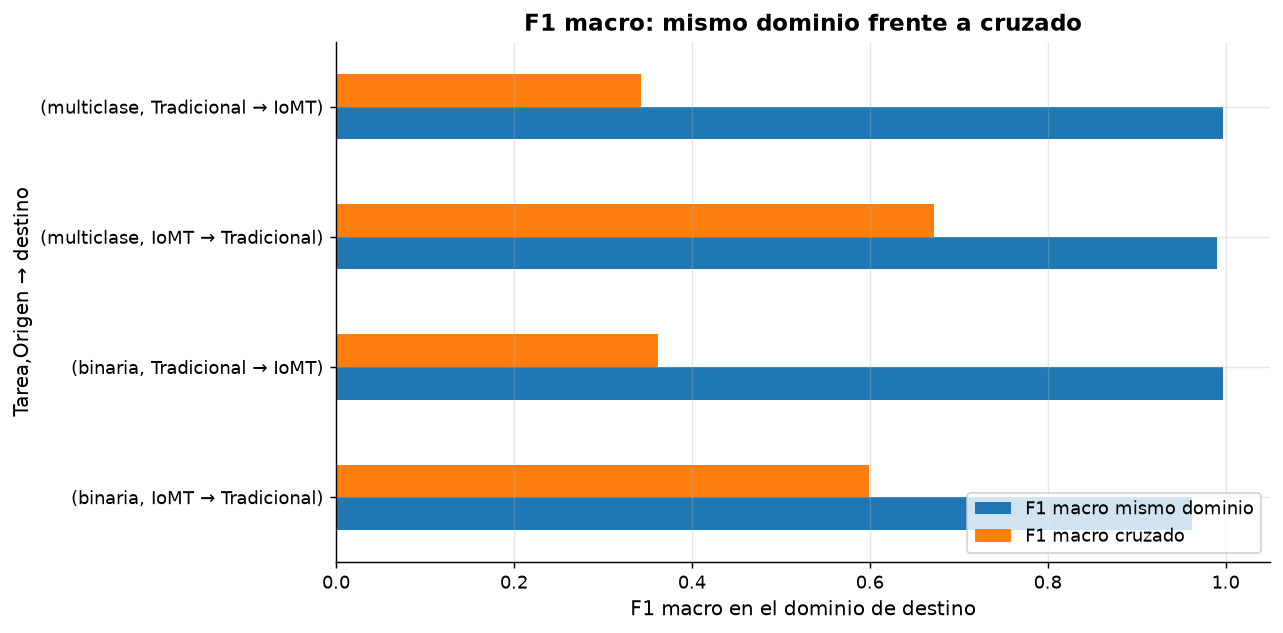

In [15]:
if HAY_TRADICIONAL:
    # Degradación: F1 macro entrenando en el destino, menos F1 macro cruzado
    degradacion = pd.DataFrame([
        {
            "Tarea": tarea,
            "Origen → destino": f"{origen} → {destino}",
            "F1 macro mismo dominio": cruzada.loc[(tarea, destino, destino), "F1 macro"],
            "F1 macro cruzado": cruzada.loc[(tarea, origen, destino), "F1 macro"],
        }
        for tarea in tareas
        for origen in dominios for destino in dominios if origen != destino
    ]).set_index(["Tarea", "Origen → destino"])
    degradacion["Degradación"] = (
        degradacion["F1 macro mismo dominio"] - degradacion["F1 macro cruzado"]
    )
    display(degradacion.round(4))
    guardar_tabla(degradacion, "degradacion_cruzada")

    ax = degradacion[["F1 macro mismo dominio", "F1 macro cruzado"]].plot.barh(
        figsize=(10, 5), title="F1 macro: mismo dominio frente a cruzado"
    )
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("F1 macro en el dominio de destino")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

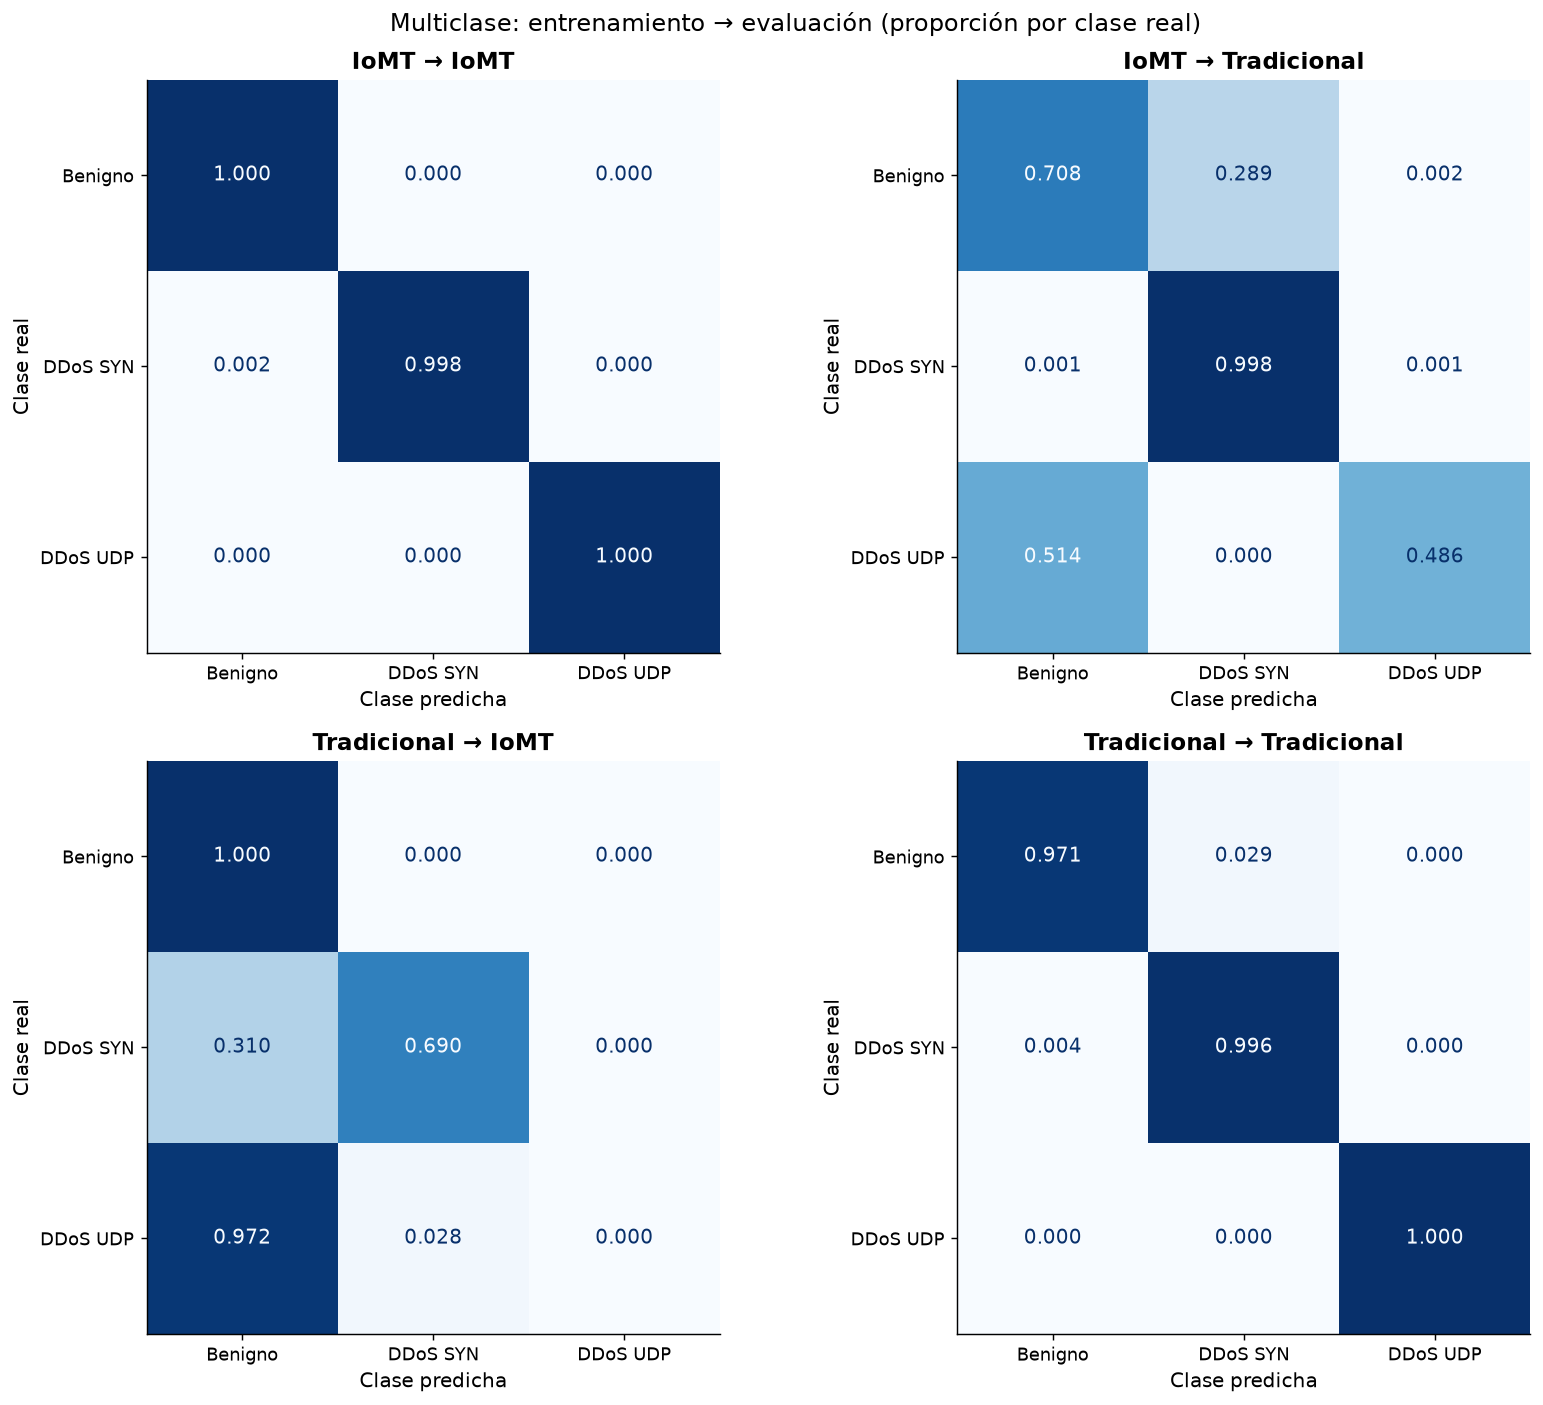

In [16]:
if HAY_TRADICIONAL:
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    combinaciones = [(o, d) for o in dominios for d in dominios]
    for ax, (origen, destino) in zip(axes.ravel(), combinaciones):
        datos = dominios[destino]["test"]
        matriz_confusion(
            datos["clase"],
            cruzados[("multiclase", origen)].predict(datos[VARIABLES_HOMOLOGADAS]),
            "multiclase", f"{origen} → {destino}", ax=ax, normalizar="true",
        )
    fig.suptitle("Multiclase: entrenamiento → evaluación (proporción por clase real)")
    plt.tight_layout()
    plt.show()

### Estabilidad de las variables comunes entre dominios

Se compara la distribución de cada variable común (ya con la longitud
alineada) entre IoMT y la red tradicional, por separado para cada clase.
Las variables con KS bajo en todas las clases son las más transferibles.
Se incluyen las banderas SYN y ACK para mostrar por qué se excluyeron.

Benigno          DDoS SYN          DDoS UDP          Resumen
                   KS      PSI       KS      PSI       KS     PSI KS medio
Variable                                                                  
bandera_ece    0.0001   0.0004   0.0000   0.0000   0.0000  0.0000   0.0000
bandera_fin    0.0178   0.1674   0.0005   0.0029   0.0002  0.0008   0.0061
bandera_cwr    0.2199   2.4530   0.0004   0.0019   0.0000  0.0000   0.0734
prop_tcp       0.2771   3.2097   0.0054   0.0095   0.0200  0.0000   0.1008
prop_udp       0.2605   2.3645   0.0015   0.0271   0.0484  0.4132   0.1035
bandera_rst    0.1704   1.4007   0.4467   4.2834   0.0000  0.0002   0.2057
bandera_psh    0.8963  12.2716   0.0109   0.0000   0.0057  0.0000   0.3043
bandera_syn    0.0140   0.1834   0.9962  13.2992   0.0001  0.0007   0.3368
long_std       0.2820   0.7435   0.4233   4.2273   0.4913  0.0000   0.3989
bandera_ack    0.9641  14.3971   0.6223   5.6265   0.0200  0.0000   0.5355
tasa_paquetes  0.6580   3.2048   0.8540   6.2058   0.5024  6.3223   0.6715
long_max       0.3140   0.8648   0.9780  10.5524   0.9986  0.0000   0.7635
long_media     0.3098   1.1616   0.9862  10.5858   0.9994  0.0007   0.7651
long_min       0.3055   1.3046   0.9941   9.9682   0.9998  0.0008   0.7665

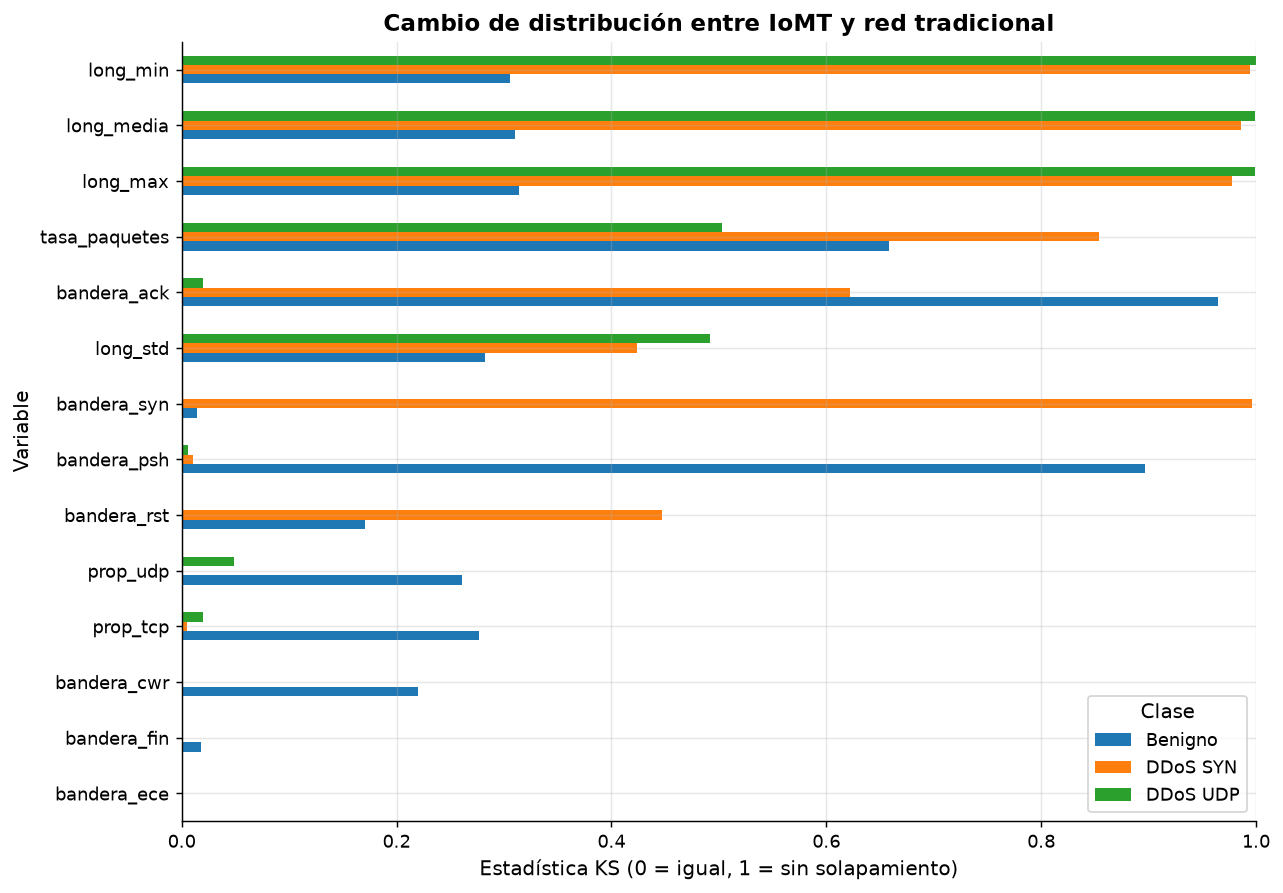

In [17]:
if HAY_TRADICIONAL:
    iomt = dominios["IoMT"]["train"]
    tradicional = dominios["Tradicional"]["train"]
    entre_dominios = pd.concat({
        nombre: estabilidad_variables(
            iomt[iomt["clase"] == clase],
            tradicional[tradicional["clase"] == clase],
            VARIABLES_COMUNES,
        )
        for clase, nombre in CLASES.items()
    }, axis=1)
    entre_dominios[("Resumen", "KS medio")] = (
        entre_dominios.xs("KS", axis=1, level=1).mean(axis=1)
    )
    entre_dominios = entre_dominios.sort_values(("Resumen", "KS medio"))
    display(entre_dominios.round(4))
    guardar_tabla(entre_dominios, "estabilidad_variables_entre_dominios")

    ks_clases = entre_dominios.drop(columns="Resumen", level=0).xs("KS", axis=1, level=1)
    ax = ks_clases.plot.barh(
        figsize=(10, 7), title="Cambio de distribución entre IoMT y red tradicional"
    )
    ax.set_xlim(0, 1)
    ax.set_xlabel("Estadística KS (0 = igual, 1 = sin solapamiento)")
    ax.legend(title="Clase", loc="lower right")
    plt.tight_layout()
    plt.show()

## 7. Guardar los modelos finales

In [18]:
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
for tarea in tareas:
    ruta = CARPETA_MODELOS / f"mejor_{tarea}.joblib"
    joblib.dump({
        "modelo": modelos[(tarea, mejor[tarea])],
        "nombre": mejor[tarea],
        "variables": variables,
        "clases": CLASES,
    }, ruta)
    print(f"{tarea}: {mejor[tarea]} → {ruta}")

binaria: LightGBM → /Users/makise/Documents/GitHub/Data-Science/models/mejor_binaria.joblib
multiclase: LightGBM → /Users/makise/Documents/GitHub/Data-Science/models/mejor_multiclase.joblib


## Conclusiones

Completar con los resultados obtenidos, siguiendo los objetivos
específicos del informe:

1. **Desempeño dentro del dominio (objetivos 2, 3 y 5):** mejora de los
   ensambles frente a la línea base en F1 macro, recall por clase y tasa
   de falsos positivos.
2. **Generalización cruzada (objetivo 4):** degradación del F1 al
   entrenar en un dominio y evaluar en otro, y qué ataques dejan de
   detectarse o se confunden.
3. **Estabilidad de variables (objetivo 6):** variables importantes y
   estables, variables importantes e inestables, y resultado de la
   prueba de robustez.
4. **Homologación (sección 6.1):** cuánto del F1 cruzado se recupera al
   corregir las diferencias de medición entre extractores, y cuánto de la
   caída se debe a diferencias reales entre redes.
5. **Limitaciones:** homologación aproximada entre extractores, error de
   CICFlowMeter-V3 en las banderas SYN/ACK, solo dos variantes de DDoS y
   prueba oficial de IoMT ya examinada.